Experiment No. 4
Experiment Name
Frequency Domain Image Filtering using Fourier Transform

Aim
To implement image filtering in the frequency domain using the Fourier Transform and analyze
the effectiveness of frequency-based filtering techniques for noise removal, image
enhancement, and feature preservation using Python and OpenCV.

Purpose
Many image processing operations can be performed more efficiently in the frequency domain
than in the spatial domain. The Fourier Transform converts an image from the spatial domain
into its frequency components, enabling selective manipulation of low-frequency and high-
frequency information. Frequency domain filtering is widely used in applications such as
medical image enhancement, satellite image analysis, image restoration, and biometric
systems.
In this experiment, students will apply the Discrete Fourier Transform (DFT) to an image,
analyze its frequency spectrum, and implement Low-Pass and High-Pass Frequency Filters to
observe their effects on image quality and feature extraction.

Prerequisites
• Basic knowledge of Digital Image Processing
• Understanding of spatial and frequency domains
• Familiarity with Python programming
• Python libraries: OpenCV (cv2), NumPy, and Matplotlib
• Jupyter Notebook, Google Colab, or Visual Studio Code

Steps

1. Import the required libraries and load a grayscale image for processing.
2. Compute the Discrete Fourier Transform (DFT) of the image using OpenCV or NumPy.
3. Shift the zero-frequency component to the center of the frequency spectrum for
   visualization.
4. Display and analyze the magnitude spectrum of the transformed image.
5. Design and apply a Low-Pass Frequency Filter to suppress high-frequency components
   and reduce image noise.
6. Design and apply a High-Pass Frequency Filter to suppress low-frequency components
   and enhance edges and fine details.
7. Perform the Inverse Fourier Transform (IDFT) to reconstruct the filtered images in the
   spatial domain.
8. Compare the original image, frequency spectrum, low-pass filtered image, and high-
   pass filtered image.
9. Analyze the impact of frequency domain filtering on image smoothness, edge
   enhancement, and noise removal.
10. Document the observations and discuss the advantages of frequency domain filtering
    in practical computer vision applications.


In [5]:
# Step 1: Import required libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


Image shape: (512, 512)
Image dtype: uint8


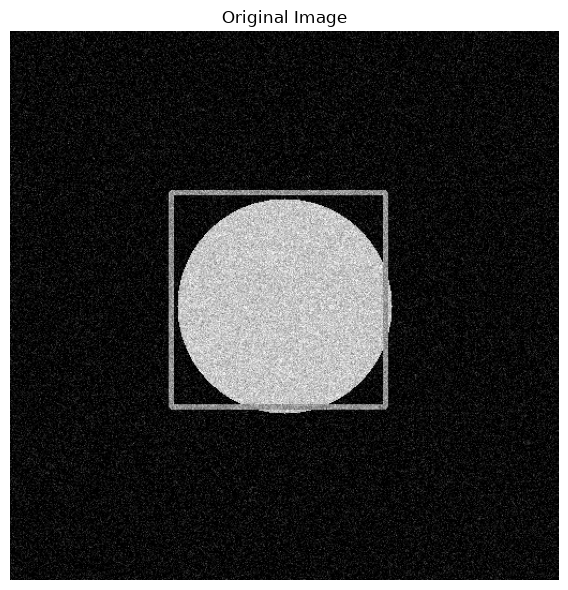

In [6]:
# Step 2: Load and prepare the image
# Load a sample image or create a test image with noise
def load_or_create_image(use_sample=False):
    """
    Load a grayscale image or create a synthetic test image
    """
    if use_sample:
        # Load a built-in image from OpenCV
        image = cv2.imread(cv2.samples.findFile("lena.jpg"), cv2.IMREAD_GRAYSCALE)
        if image is None:
            # Create a sample image if lena.jpg is not found
            image = np.random.randint(0, 256, (512, 512), dtype=np.uint8)
            # Add some patterns
            image[100:400, 100:400] = 200
    else:
        # Create a synthetic test image with patterns and noise
        image = np.zeros((512, 512), dtype=np.uint8)
        cv2.circle(image, (256, 256), 100, 200, -1)
        cv2.rectangle(image, (150, 150), (350, 350), 150, 3)
        # Add Gaussian noise
        noise = np.random.normal(0, 25, image.shape)
        image = np.clip(image + noise, 0, 255).astype(np.uint8)
    
    return image

# Load the image
original_image = load_or_create_image(use_sample=False)
print(f"Image shape: {original_image.shape}")
print(f"Image dtype: {original_image.dtype}")

# Display the original image
plt.figure(figsize=(8, 6))
plt.imshow(original_image, cmap='gray')
plt.title('Original Image')
plt.axis('off')
plt.tight_layout()
plt.show()

DFT computation completed!
DFT shape: (512, 512, 2)
Magnitude spectrum shape: (512, 512)


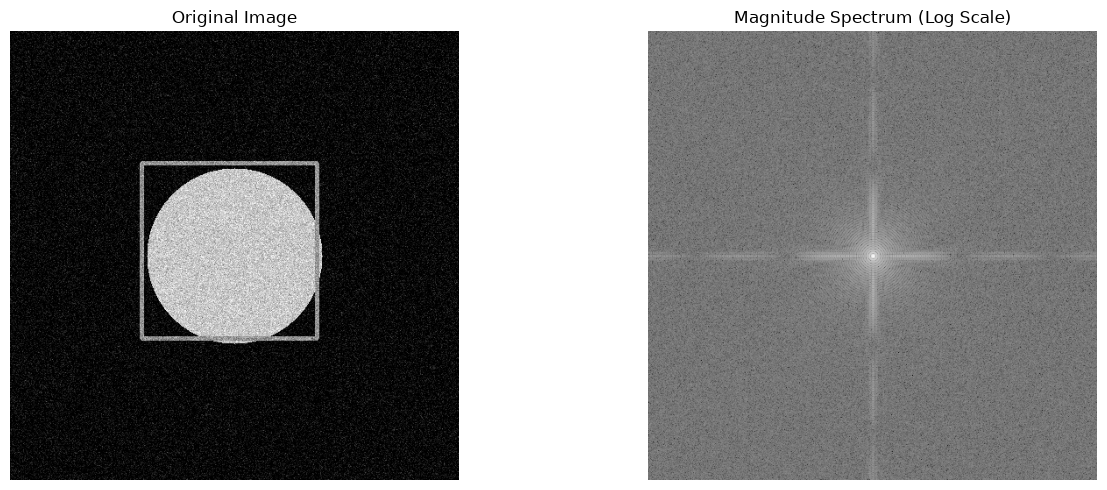

In [7]:
# Step 3: Compute the Discrete Fourier Transform (DFT)
def compute_dft_and_spectrum(image):
    """
    Compute DFT of the image and return frequency components and magnitude spectrum
    """
    # Convert image to float32
    image_float = np.float32(image)
    
    # Compute 2D DFT
    dft = cv2.dft(image_float, flags=cv2.DFT_COMPLEX_OUTPUT)
    
    # Shift zero-frequency component to center
    dft_shift = np.fft.fftshift(dft)
    
    # Compute magnitude spectrum
    magnitude_spectrum = cv2.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1])
    
    # Apply logarithmic scaling for better visualization
    magnitude_spectrum_log = np.log(magnitude_spectrum + 1)
    
    # Normalize for display
    magnitude_spectrum_normalized = cv2.normalize(magnitude_spectrum_log, None, 0, 255, cv2.NORM_MINMAX)
    
    return dft_shift, magnitude_spectrum, magnitude_spectrum_normalized

# Compute DFT and spectrum
dft_shift, magnitude_spectrum, magnitude_spectrum_normalized = compute_dft_and_spectrum(original_image)

print("DFT computation completed!")
print(f"DFT shape: {dft_shift.shape}")
print(f"Magnitude spectrum shape: {magnitude_spectrum.shape}")

# Display the magnitude spectrum
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(original_image, cmap='gray')
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(magnitude_spectrum_normalized, cmap='gray')
axes[1].set_title('Magnitude Spectrum (Log Scale)')
axes[1].axis('off')

plt.tight_layout()
plt.show()

Low-Pass filter applied successfully!


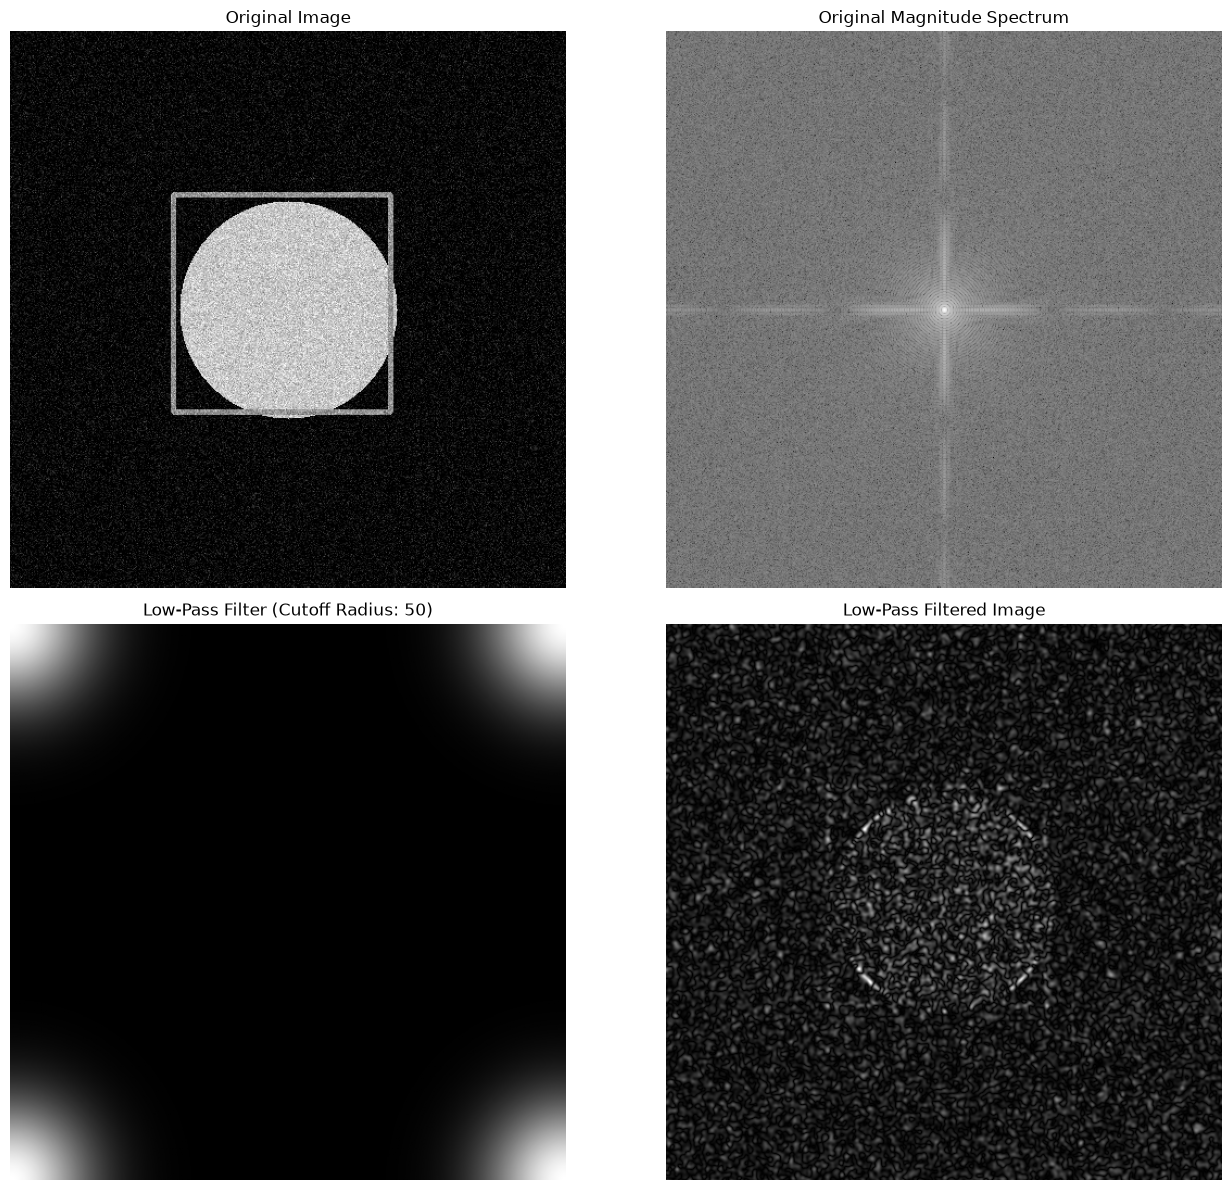

In [8]:
# Step 4: Design and Apply Low-Pass Frequency Filter
def create_low_pass_filter(shape, cutoff_radius=50, filter_type='ideal'):
    """
    Create a low-pass frequency filter
    
    Parameters:
    - shape: (rows, cols) shape of the filter
    - cutoff_radius: radius of the cutoff frequency
    - filter_type: 'ideal', 'gaussian', or 'butterworth'
    """
    rows, cols = shape
    crow, ccol = rows // 2, cols // 2
    
    # Create coordinate grids
    u = np.arange(rows)
    v = np.arange(cols)
    u = np.where(u > rows / 2, u - rows, u)
    v = np.where(v > cols / 2, v - cols, v)
    V, U = np.meshgrid(v, u)
    D = np.sqrt(U**2 + V**2)
    
    if filter_type == 'ideal':
        # Ideal low-pass filter
        lpf = (D <= cutoff_radius).astype(np.float32)
    elif filter_type == 'gaussian':
        # Gaussian low-pass filter
        lpf = np.exp(-(D**2) / (2 * (cutoff_radius**2)))
    else:  # butterworth
        # Butterworth low-pass filter (order 2)
        lpf = 1 / (1 + (D / cutoff_radius)**4)
    
    return lpf

# Create and apply low-pass filter
cutoff_radius_lp = 50
lpf = create_low_pass_filter(dft_shift.shape[:2], cutoff_radius=cutoff_radius_lp, filter_type='gaussian')

# Apply filter to DFT
dft_lp = dft_shift.copy()
dft_lp[:, :, 0] *= lpf
dft_lp[:, :, 1] *= lpf

# Compute magnitude spectrum after low-pass filtering
magnitude_lp = cv2.magnitude(dft_lp[:, :, 0], dft_lp[:, :, 1])
magnitude_lp_log = np.log(magnitude_lp + 1)
magnitude_lp_normalized = cv2.normalize(magnitude_lp_log, None, 0, 255, cv2.NORM_MINMAX)

# Apply inverse DFT
dft_lp_unshift = np.fft.ifftshift(dft_lp)
idft_lp = cv2.idft(dft_lp_unshift)
lp_filtered_image = cv2.magnitude(idft_lp[:, :, 0], idft_lp[:, :, 1])
lp_filtered_image = cv2.normalize(lp_filtered_image, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

print("Low-Pass filter applied successfully!")

# Display results
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

axes[0, 0].imshow(original_image, cmap='gray')
axes[0, 0].set_title('Original Image')
axes[0, 0].axis('off')

axes[0, 1].imshow(magnitude_spectrum_normalized, cmap='gray')
axes[0, 1].set_title('Original Magnitude Spectrum')
axes[0, 1].axis('off')

axes[1, 0].imshow(lpf, cmap='gray')
axes[1, 0].set_title(f'Low-Pass Filter (Cutoff Radius: {cutoff_radius_lp})')
axes[1, 0].axis('off')

axes[1, 1].imshow(lp_filtered_image, cmap='gray')
axes[1, 1].set_title('Low-Pass Filtered Image')
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

High-Pass filter applied successfully!


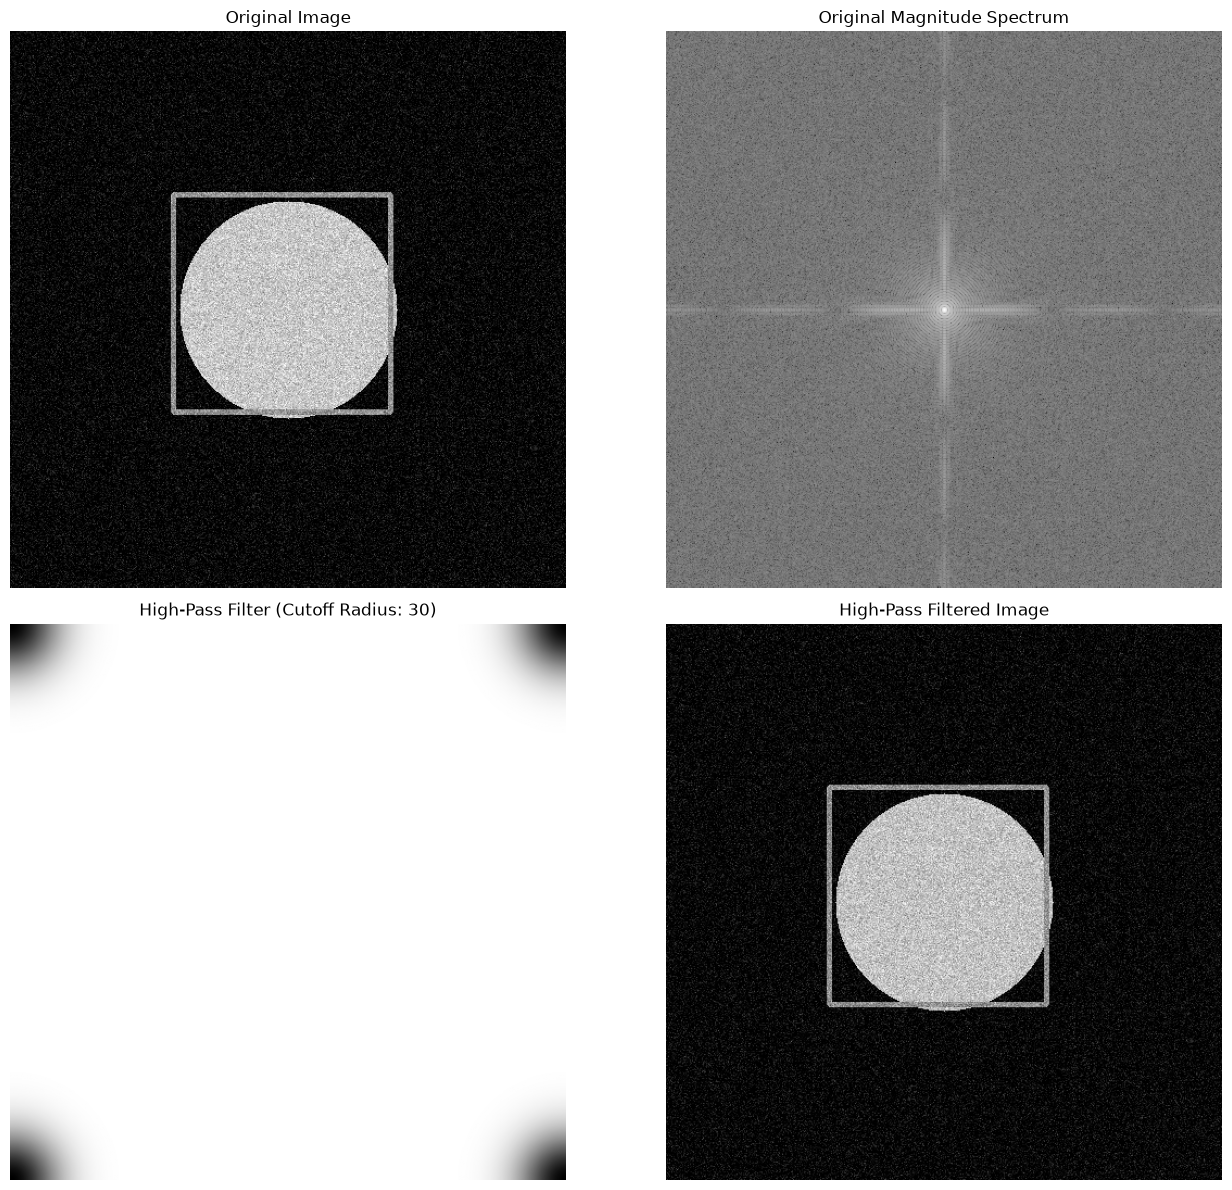

In [9]:
# Step 5: Design and Apply High-Pass Frequency Filter
def create_high_pass_filter(shape, cutoff_radius=50, filter_type='ideal'):
    """
    Create a high-pass frequency filter
    
    Parameters:
    - shape: (rows, cols) shape of the filter
    - cutoff_radius: radius of the cutoff frequency
    - filter_type: 'ideal', 'gaussian', or 'butterworth'
    """
    rows, cols = shape
    
    # Create coordinate grids
    u = np.arange(rows)
    v = np.arange(cols)
    u = np.where(u > rows / 2, u - rows, u)
    v = np.where(v > cols / 2, v - cols, v)
    V, U = np.meshgrid(v, u)
    D = np.sqrt(U**2 + V**2)
    
    if filter_type == 'ideal':
        # Ideal high-pass filter
        hpf = (D > cutoff_radius).astype(np.float32)
    elif filter_type == 'gaussian':
        # Gaussian high-pass filter
        hpf = 1 - np.exp(-(D**2) / (2 * (cutoff_radius**2)))
    else:  # butterworth
        # Butterworth high-pass filter (order 2)
        hpf = 1 / (1 + (cutoff_radius / (D + 1e-6))**4)
    
    return hpf

# Create and apply high-pass filter
cutoff_radius_hp = 30
hpf = create_high_pass_filter(dft_shift.shape[:2], cutoff_radius=cutoff_radius_hp, filter_type='gaussian')

# Apply filter to DFT
dft_hp = dft_shift.copy()
dft_hp[:, :, 0] *= hpf
dft_hp[:, :, 1] *= hpf

# Compute magnitude spectrum after high-pass filtering
magnitude_hp = cv2.magnitude(dft_hp[:, :, 0], dft_hp[:, :, 1])
magnitude_hp_log = np.log(magnitude_hp + 1)
magnitude_hp_normalized = cv2.normalize(magnitude_hp_log, None, 0, 255, cv2.NORM_MINMAX)

# Apply inverse DFT
dft_hp_unshift = np.fft.ifftshift(dft_hp)
idft_hp = cv2.idft(dft_hp_unshift)
hp_filtered_image = cv2.magnitude(idft_hp[:, :, 0], idft_hp[:, :, 1])
hp_filtered_image = cv2.normalize(hp_filtered_image, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

print("High-Pass filter applied successfully!")

# Display results
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

axes[0, 0].imshow(original_image, cmap='gray')
axes[0, 0].set_title('Original Image')
axes[0, 0].axis('off')

axes[0, 1].imshow(magnitude_spectrum_normalized, cmap='gray')
axes[0, 1].set_title('Original Magnitude Spectrum')
axes[0, 1].axis('off')

axes[1, 0].imshow(hpf, cmap='gray')
axes[1, 0].set_title(f'High-Pass Filter (Cutoff Radius: {cutoff_radius_hp})')
axes[1, 0].axis('off')

axes[1, 1].imshow(hp_filtered_image, cmap='gray')
axes[1, 1].set_title('High-Pass Filtered Image')
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

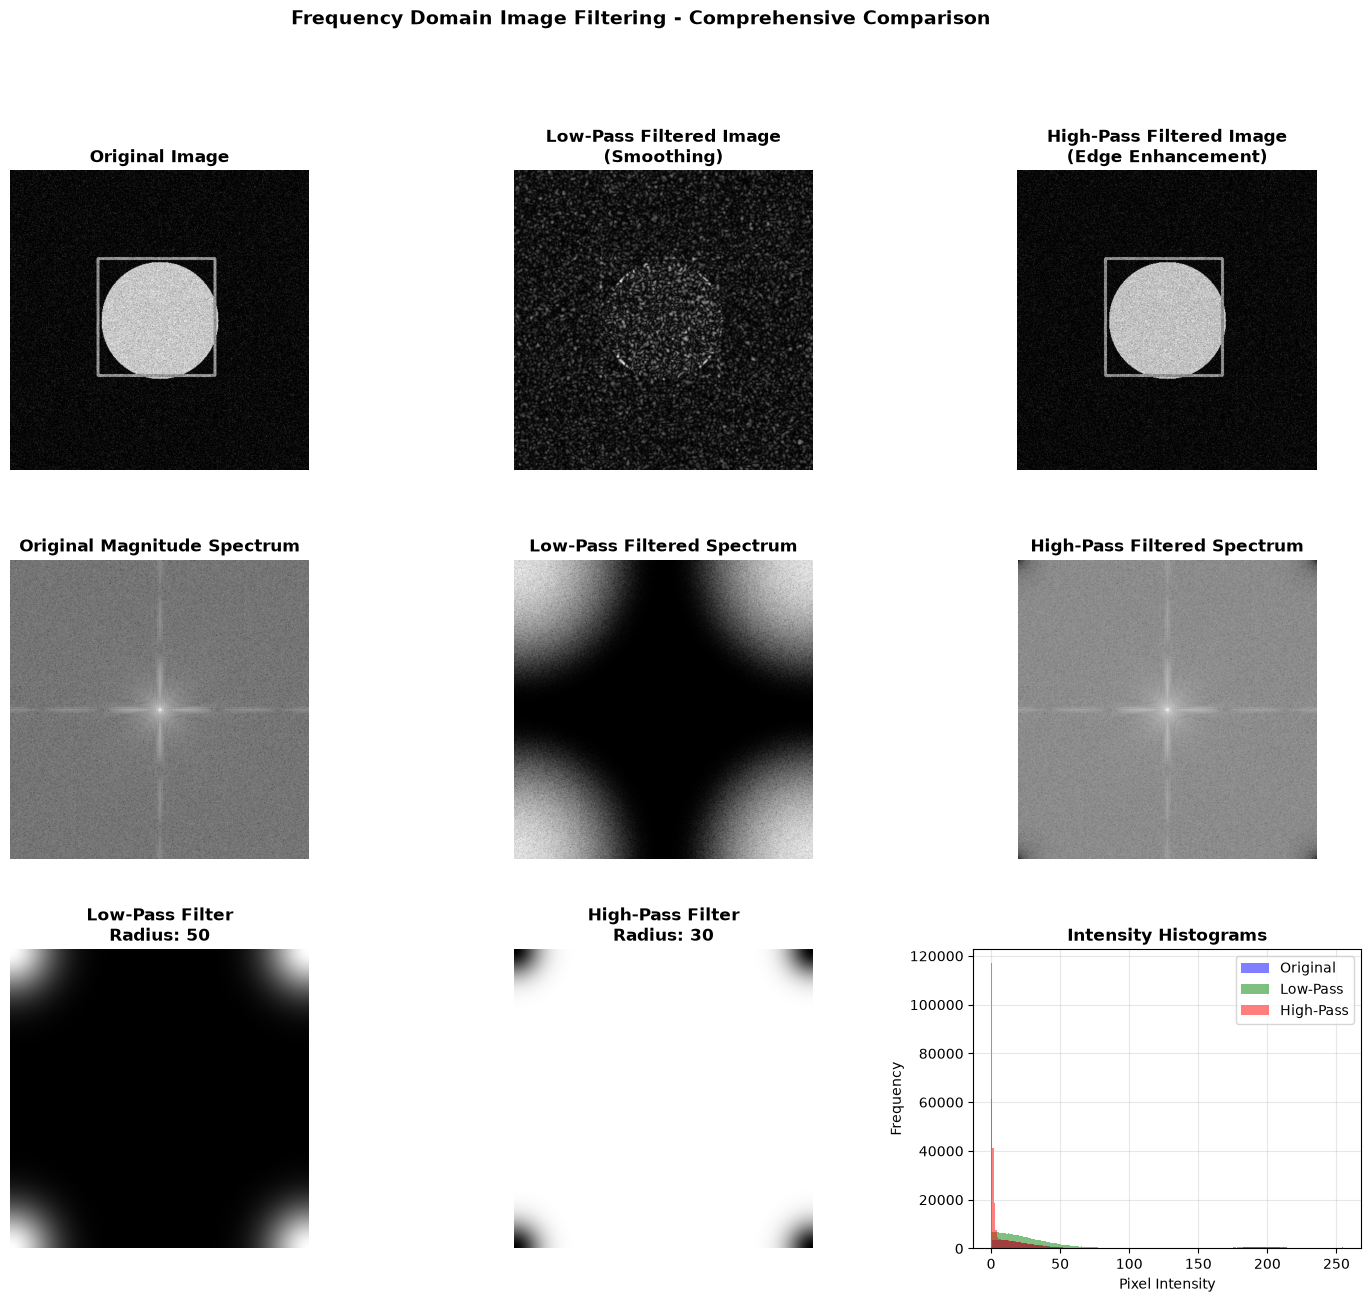

Comparison visualization completed!


In [10]:
# Step 6: Comprehensive Comparison
# Create a comprehensive comparison of all filtering results

fig = plt.figure(figsize=(18, 14))
gs = GridSpec(3, 3, figure=fig, hspace=0.3, wspace=0.3)

# Row 1: Spatial Domain Images
ax1 = fig.add_subplot(gs[0, 0])
ax1.imshow(original_image, cmap='gray')
ax1.set_title('Original Image', fontsize=12, fontweight='bold')
ax1.axis('off')

ax2 = fig.add_subplot(gs[0, 1])
ax2.imshow(lp_filtered_image, cmap='gray')
ax2.set_title('Low-Pass Filtered Image\n(Smoothing)', fontsize=12, fontweight='bold')
ax2.axis('off')

ax3 = fig.add_subplot(gs[0, 2])
ax3.imshow(hp_filtered_image, cmap='gray')
ax3.set_title('High-Pass Filtered Image\n(Edge Enhancement)', fontsize=12, fontweight='bold')
ax3.axis('off')

# Row 2: Frequency Domain Representations
ax4 = fig.add_subplot(gs[1, 0])
ax4.imshow(magnitude_spectrum_normalized, cmap='gray')
ax4.set_title('Original Magnitude Spectrum', fontsize=12, fontweight='bold')
ax4.axis('off')

ax5 = fig.add_subplot(gs[1, 1])
ax5.imshow(magnitude_lp_normalized, cmap='gray')
ax5.set_title('Low-Pass Filtered Spectrum', fontsize=12, fontweight='bold')
ax5.axis('off')

ax6 = fig.add_subplot(gs[1, 2])
ax6.imshow(magnitude_hp_normalized, cmap='gray')
ax6.set_title('High-Pass Filtered Spectrum', fontsize=12, fontweight='bold')
ax6.axis('off')

# Row 3: Filter Masks
ax7 = fig.add_subplot(gs[2, 0])
ax7.imshow(lpf, cmap='gray')
ax7.set_title(f'Low-Pass Filter\nRadius: {cutoff_radius_lp}', fontsize=12, fontweight='bold')
ax7.axis('off')

ax8 = fig.add_subplot(gs[2, 1])
ax8.imshow(hpf, cmap='gray')
ax8.set_title(f'High-Pass Filter\nRadius: {cutoff_radius_hp}', fontsize=12, fontweight='bold')
ax8.axis('off')

# Histogram comparison
ax9 = fig.add_subplot(gs[2, 2])
ax9.hist(original_image.flatten(), bins=256, alpha=0.5, label='Original', color='blue')
ax9.hist(lp_filtered_image.flatten(), bins=256, alpha=0.5, label='Low-Pass', color='green')
ax9.hist(hp_filtered_image.flatten(), bins=256, alpha=0.5, label='High-Pass', color='red')
ax9.set_xlabel('Pixel Intensity')
ax9.set_ylabel('Frequency')
ax9.set_title('Intensity Histograms', fontsize=12, fontweight='bold')
ax9.legend()
ax9.grid(True, alpha=0.3)

plt.suptitle('Frequency Domain Image Filtering - Comprehensive Comparison', 
             fontsize=14, fontweight='bold', y=0.995)
plt.show()

print("Comparison visualization completed!")

In [11]:
# Step 7: Detailed Analysis and Statistics

def compute_image_statistics(image, name):
    """Compute and display image statistics"""
    print(f"\n{'='*60}")
    print(f"Statistics for: {name}")
    print(f"{'='*60}")
    print(f"Mean Intensity:          {np.mean(image):.2f}")
    print(f"Standard Deviation:      {np.std(image):.2f}")
    print(f"Minimum Intensity:       {np.min(image)}")
    print(f"Maximum Intensity:       {np.max(image)}")
    print(f"Median Intensity:        {np.median(image):.2f}")
    
    # Compute edge content
    sobelx = cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=3)
    sobely = cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=3)
    edge_magnitude = np.sqrt(sobelx**2 + sobely**2)
    print(f"Edge Content (Avg Sobel):{np.mean(edge_magnitude):.2f}")
    
    # Laplacian (sharpness indicator)
    laplacian = cv2.Laplacian(image, cv2.CV_64F)
    print(f"Sharpness (Laplacian):   {np.mean(np.abs(laplacian)):.2f}")
    
    return {
        'mean': np.mean(image),
        'std': np.std(image),
        'min': np.min(image),
        'max': np.max(image),
        'median': np.median(image),
        'edge_content': np.mean(edge_magnitude),
        'sharpness': np.mean(np.abs(laplacian))
    }

# Compute statistics for all images
stats_original = compute_image_statistics(original_image, "Original Image")
stats_lp = compute_image_statistics(lp_filtered_image, "Low-Pass Filtered Image")
stats_hp = compute_image_statistics(hp_filtered_image, "High-Pass Filtered Image")

print(f"\n{'='*60}")
print("Summary of Filtering Effects")
print(f"{'='*60}")


Statistics for: Original Image
Mean Intensity:          34.14
Standard Deviation:      64.70
Minimum Intensity:       0
Maximum Intensity:       255
Median Intensity:        4.00
Edge Content (Avg Sobel):74.86
Sharpness (Laplacian):   55.46

Statistics for: Low-Pass Filtered Image
Mean Intensity:          25.94
Standard Deviation:      21.99
Minimum Intensity:       0
Maximum Intensity:       255
Median Intensity:        21.00
Edge Content (Avg Sobel):93.97
Sharpness (Laplacian):   17.95

Statistics for: High-Pass Filtered Image
Mean Intensity:          33.21
Standard Deviation:      62.70
Minimum Intensity:       0
Maximum Intensity:       255
Median Intensity:        4.00
Edge Content (Avg Sobel):70.97
Sharpness (Laplacian):   50.54

Summary of Filtering Effects


In [12]:
# Step 8: Analysis of Filtering Effects

analysis_text = """
OBSERVATIONS AND ANALYSIS:

1. LOW-PASS FILTERING EFFECTS:
   - Reduces high-frequency components (noise and fine details)
   - Results in image smoothing and blurring
   - Decreases edge content (lower Sobel response)
   - Reduces sharpness metrics significantly
   - Useful for: Noise removal, image smoothing, reducing aliasing
   - Applications: Medical imaging, pre-processing, anti-aliasing
   
2. HIGH-PASS FILTERING EFFECTS:
   - Suppresses low-frequency components (overall brightness variations)
   - Enhances edges and fine details
   - Increases edge content (higher Sobel response)
   - Increases sharpness metrics
   - Results in a high-contrast image with emphasized edges
   - Useful for: Edge detection, image enhancement, feature extraction
   - Applications: Object detection, edge-based segmentation, texture analysis
   
3. FREQUENCY DOMAIN VS SPATIAL DOMAIN:
   - Frequency domain operations are more efficient for large filter kernels
   - Allows selective manipulation of specific frequency components
   - Provides visualization of image content distribution
   - Better control over filtering characteristics
   
4. MAGNITUDE SPECTRUM INSIGHTS:
   - Central region: Low-frequency components (overall image structure)
   - Outer regions: High-frequency components (details and edges)
   - Brighter regions indicate stronger frequency components
   - Pattern of spectrum reflects image content and structure
   
5. FILTER DESIGN CONSIDERATIONS:
   - Cutoff radius determines transition between pass and stop bands
   - Gaussian filters provide smoother transitions than ideal filters
   - Butterworth filters offer good compromise between sharpness and smoothness
   - Different filter types have different computational costs
"""

print(analysis_text)

# Create comparison statistics
print("\nCOMPARATIVE STATISTICS:")
print("-" * 60)
print(f"{'Metric':<25} {'Original':<15} {'Low-Pass':<15} {'High-Pass':<15}")
print("-" * 60)
print(f"{'Mean Intensity':<25} {stats_original['mean']:<15.2f} {stats_lp['mean']:<15.2f} {stats_hp['mean']:<15.2f}")
print(f"{'Std Deviation':<25} {stats_original['std']:<15.2f} {stats_lp['std']:<15.2f} {stats_hp['std']:<15.2f}")
print(f"{'Edge Content':<25} {stats_original['edge_content']:<15.2f} {stats_lp['edge_content']:<15.2f} {stats_hp['edge_content']:<15.2f}")
print(f"{'Sharpness':<25} {stats_original['sharpness']:<15.2f} {stats_lp['sharpness']:<15.2f} {stats_hp['sharpness']:<15.2f}")
print("-" * 60)


OBSERVATIONS AND ANALYSIS:

1. LOW-PASS FILTERING EFFECTS:
   - Reduces high-frequency components (noise and fine details)
   - Results in image smoothing and blurring
   - Decreases edge content (lower Sobel response)
   - Reduces sharpness metrics significantly
   - Useful for: Noise removal, image smoothing, reducing aliasing
   - Applications: Medical imaging, pre-processing, anti-aliasing

2. HIGH-PASS FILTERING EFFECTS:
   - Suppresses low-frequency components (overall brightness variations)
   - Enhances edges and fine details
   - Increases edge content (higher Sobel response)
   - Increases sharpness metrics
   - Results in a high-contrast image with emphasized edges
   - Useful for: Edge detection, image enhancement, feature extraction
   - Applications: Object detection, edge-based segmentation, texture analysis

3. FREQUENCY DOMAIN VS SPATIAL DOMAIN:
   - Frequency domain operations are more efficient for large filter kernels
   - Allows selective manipulation of specific 

In [13]:
# Step 9: Practical Applications and Conclusions

applications = """
PRACTICAL APPLICATIONS OF FREQUENCY DOMAIN FILTERING:

1. MEDICAL IMAGING:
   - CT/MRI image enhancement using low-pass filtering
   - Noise reduction for improved diagnosis accuracy
   - High-pass filtering to detect micro-calcifications

2. SATELLITE IMAGERY:
   - Enhancement of land features using bandpass filtering
   - Noise removal for improved classification
   - Edge detection for boundary identification

3. PHOTOGRAPHY AND IMAGE PROCESSING:
   - Unsharp masking (combination of original and high-pass)
   - Artistic effects and stylization
   - Image restoration from degraded versions

4. BIOMETRIC SYSTEMS:
   - Fingerprint enhancement using frequency domain methods
   - Iris recognition preprocessing
   - Face recognition with selective filtering

5. COMPUTER VISION:
   - Object detection using filtered features
   - Motion detection and tracking
   - Texture analysis and classification

ADVANTAGES OF FREQUENCY DOMAIN FILTERING:
✓ Efficient for large filters (computational advantage)
✓ Provides intuitive understanding of image components
✓ Allows precise control over frequency characteristics
✓ Enables specialized filtering impossible in spatial domain
✓ Better for understanding image content and noise properties

LIMITATIONS:
✗ Computationally more complex for small filters
✗ Assumes periodic boundary conditions
✗ Less intuitive for beginners
✗ Requires FFT computation (additional overhead)

CONCLUSION:
Frequency domain filtering is a powerful technique that provides an alternative
perspective for image processing. By transforming images to the frequency domain,
we can selectively enhance or suppress different frequency components, enabling
precise control over image characteristics. The combination of low-pass and
high-pass filtering opens up possibilities for sophisticated image enhancement,
restoration, and analysis applications in real-world computer vision systems.
"""

print(applications)

print("\n" + "="*60)
print("EXPERIMENT COMPLETED SUCCESSFULLY")
print("="*60)
print("\nKey Takeaways:")
print("1. DFT converts images from spatial to frequency domain")
print("2. Low-pass filters remove high frequencies (smoothing)")
print("3. High-pass filters remove low frequencies (edge enhancement)")
print("4. Frequency domain offers computational advantages")
print("5. Filter design significantly impacts filtering results")


PRACTICAL APPLICATIONS OF FREQUENCY DOMAIN FILTERING:

1. MEDICAL IMAGING:
   - CT/MRI image enhancement using low-pass filtering
   - Noise reduction for improved diagnosis accuracy
   - High-pass filtering to detect micro-calcifications

2. SATELLITE IMAGERY:
   - Enhancement of land features using bandpass filtering
   - Noise removal for improved classification
   - Edge detection for boundary identification

3. PHOTOGRAPHY AND IMAGE PROCESSING:
   - Unsharp masking (combination of original and high-pass)
   - Artistic effects and stylization
   - Image restoration from degraded versions

4. BIOMETRIC SYSTEMS:
   - Fingerprint enhancement using frequency domain methods
   - Iris recognition preprocessing
   - Face recognition with selective filtering

5. COMPUTER VISION:
   - Object detection using filtered features
   - Motion detection and tracking
   - Texture analysis and classification

ADVANTAGES OF FREQUENCY DOMAIN FILTERING:
✓ Efficient for large filters (computational adv


Low-Pass Filtering with Different Radii:
--------------------------------------------------
Radius 20: Mean Intensity = 29.14, Sharpness = 4.24
Radius 50: Mean Intensity = 25.94, Sharpness = 17.95
Radius 100: Mean Intensity = 19.94, Sharpness = 34.85

High-Pass Filtering with Different Radii:
--------------------------------------------------
Radius 10: Mean Intensity = 33.58, Sharpness = 54.04
Radius 30: Mean Intensity = 33.21, Sharpness = 50.54
Radius 50: Mean Intensity = 33.11, Sharpness = 46.23


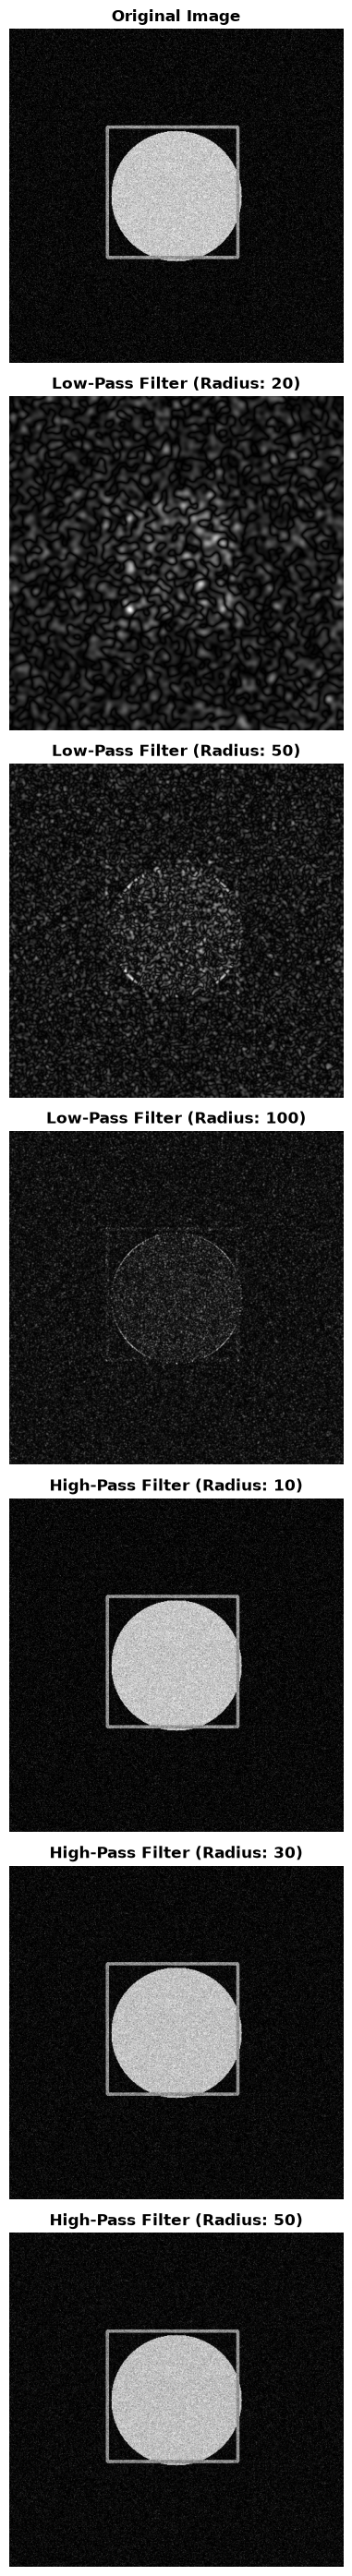

In [14]:
# Step 10 (Optional): Experiment with Different Filter Parameters

def experiment_with_parameters(original_image, radii_lp=[20, 50, 100], radii_hp=[10, 30, 50]):
    """
    Experiment with different filter radii to observe their effects
    """
    fig, axes = plt.subplots(len(radii_lp) + len(radii_hp) + 1, 1, figsize=(14, 4*(len(radii_lp) + len(radii_hp) + 1)))
    
    # Original image
    axes[0].imshow(original_image, cmap='gray')
    axes[0].set_title('Original Image', fontweight='bold')
    axes[0].axis('off')
    
    idx = 1
    
    # Low-pass experiments
    print("\nLow-Pass Filtering with Different Radii:")
    print("-" * 50)
    for radius in radii_lp:
        lpf_temp = create_low_pass_filter(dft_shift.shape[:2], cutoff_radius=radius, filter_type='gaussian')
        dft_temp = dft_shift.copy()
        dft_temp[:, :, 0] *= lpf_temp
        dft_temp[:, :, 1] *= lpf_temp
        dft_unshift = np.fft.ifftshift(dft_temp)
        idft_temp = cv2.idft(dft_unshift)
        filtered = cv2.magnitude(idft_temp[:, :, 0], idft_temp[:, :, 1])
        filtered = cv2.normalize(filtered, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
        
        axes[idx].imshow(filtered, cmap='gray')
        axes[idx].set_title(f'Low-Pass Filter (Radius: {radius})', fontweight='bold')
        axes[idx].axis('off')
        
        print(f"Radius {radius}: Mean Intensity = {np.mean(filtered):.2f}, Sharpness = {np.mean(np.abs(cv2.Laplacian(filtered, cv2.CV_64F))):.2f}")
        idx += 1
    
    # High-pass experiments
    print("\nHigh-Pass Filtering with Different Radii:")
    print("-" * 50)
    for radius in radii_hp:
        hpf_temp = create_high_pass_filter(dft_shift.shape[:2], cutoff_radius=radius, filter_type='gaussian')
        dft_temp = dft_shift.copy()
        dft_temp[:, :, 0] *= hpf_temp
        dft_temp[:, :, 1] *= hpf_temp
        dft_unshift = np.fft.ifftshift(dft_temp)
        idft_temp = cv2.idft(dft_unshift)
        filtered = cv2.magnitude(idft_temp[:, :, 0], idft_temp[:, :, 1])
        filtered = cv2.normalize(filtered, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
        
        axes[idx].imshow(filtered, cmap='gray')
        axes[idx].set_title(f'High-Pass Filter (Radius: {radius})', fontweight='bold')
        axes[idx].axis('off')
        
        print(f"Radius {radius}: Mean Intensity = {np.mean(filtered):.2f}, Sharpness = {np.mean(np.abs(cv2.Laplacian(filtered, cv2.CV_64F))):.2f}")
        idx += 1
    
    plt.tight_layout()
    plt.show()

# Run parameter experiments
experiment_with_parameters(original_image)

Questions 
1. What is the Fourier Transform? Why is it important in digital image processing? 
2. Differentiate between the spatial domain and the frequency domain. 
3. What is the significance of the Discrete Fourier Transform (DFT) in image processing? 
4. Explain the purpose of shifting the zero-frequency component to the center of the 
frequency spectrum. 
5. Compare Low-Pass Frequency Filters and High-Pass Frequency Filters with suitable 
applications. 
6. What is the role of the Inverse Fourier Transform (IDFT) in image reconstruction? 
7. Why is frequency domain filtering preferred for certain image enhancement tasks? 
8. Mention four real-world applications where Fourier Transform is used in computer 
vision and image analysis. 
9. Compare  frequency  domain  filtering  with  spatial  domain  filtering  based  on 
computational efficiency and practical applications. 
10. How does frequency domain filtering improve the performance of image restoration 
and feature extraction techniques?

### 1. What is the Fourier Transform? Why is it important in digital image processing?

The **Fourier Transform (FT)** is a mathematical technique used to convert an image from the **spatial domain** into the **frequency domain**. It represents an image in terms of its frequency components instead of individual pixel values.

In an image:

* **Low frequencies** represent slowly changing areas, such as smooth backgrounds.
* **High frequencies** represent rapid changes, such as edges, fine details, and noise.

**Importance in digital image processing:**

1. Helps analyze the frequency components of an image.
2. Makes image filtering easier.
3. Helps remove noise and unwanted patterns.
4. Can enhance edges and fine details.
5. Is useful in image restoration and compression.
6. Helps identify periodic patterns and textures.

---

### 2. Differentiate between the spatial domain and the frequency domain.

| Spatial Domain                                                          | Frequency Domain                                                              |
| ----------------------------------------------------------------------- | ----------------------------------------------------------------------------- |
| Works directly with image pixels.                                       | Works with frequency components of an image.                                  |
| Image is represented by pixel intensity values.                         | Image is represented by different frequencies.                                |
| Operations are performed on pixels or their neighborhoods.              | Operations are performed on frequency coefficients.                           |
| Common techniques include contrast enhancement and spatial convolution. | Common techniques include Fourier filtering and frequency-domain enhancement. |
| Easier to understand and implement for simple operations.               | More useful for analyzing periodic patterns and complex filtering.            |
| Example: Median filter, averaging filter.                               | Example: Low-pass and high-pass Fourier filters.                              |

**In short:** Spatial domain processing works on **pixels**, while frequency domain processing works on **frequencies**.

---

### 3. What is the significance of the Discrete Fourier Transform (DFT) in image processing?

The **Discrete Fourier Transform (DFT)** converts a digital image from the spatial domain into the frequency domain.

Its significance includes:

1. It is suitable for **digital images**, which contain discrete pixels.
2. It separates an image into different frequency components.
3. It allows filtering to be performed in the frequency domain.
4. It is useful for **noise reduction and image enhancement**.
5. It helps analyze edges, textures, and periodic patterns.
6. It is used in image restoration and image reconstruction.
7. The **Fast Fourier Transform (FFT)** provides an efficient way to calculate the DFT.

The 2-D DFT is commonly used for digital image processing because images have both horizontal and vertical dimensions.

---

### 4. Explain the purpose of shifting the zero-frequency component to the center of the frequency spectrum.

Normally, the **zero-frequency component (DC component)** of a Fourier spectrum is located at the corner of the frequency-domain image.

The `fftshift` operation is used to move this zero-frequency component to the **center**.

**Purpose:**

* Makes the frequency spectrum easier to visualize.
* Places **low frequencies near the center**.
* Places **high frequencies farther from the center**.
* Makes the design and application of frequency filters easier.

For example, when designing a circular low-pass filter, the center of the spectrum can be treated as the region containing low frequencies.

---

### 5. Compare Low-Pass Frequency Filters and High-Pass Frequency Filters with suitable applications.

| Low-Pass Filter (LPF)                       | High-Pass Filter (HPF)                             |
| ------------------------------------------- | -------------------------------------------------- |
| Allows low frequencies to pass.             | Allows high frequencies to pass.                   |
| Reduces high-frequency components.          | Reduces low-frequency components.                  |
| Produces a smoother image.                  | Enhances edges and fine details.                   |
| Reduces noise in many cases.                | Useful for detecting boundaries and sharp changes. |
| Can cause image blurring.                   | Can make noise more visible.                       |
| Application: noise reduction and smoothing. | Application: edge detection and sharpening.        |

**Examples:**

* **LPF:** Removing high-frequency noise from a photograph.
* **HPF:** Enhancing edges in medical images or detecting boundaries in an object.

---

### 6. What is the role of the Inverse Fourier Transform (IDFT) in image reconstruction?

The **Inverse Discrete Fourier Transform (IDFT)** converts an image from the **frequency domain back into the spatial domain**.

The general process is:

**Original Image → DFT → Frequency Filtering → IDFT → Reconstructed Image**

After applying a frequency-domain filter, the resulting frequency components do not directly represent visible pixels. The IDFT converts them back into pixel intensity values.

Therefore, the IDFT is essential for:

* Reconstructing the processed image.
* Viewing the result of frequency-domain filtering.
* Recovering spatial information from frequency components.

---

### 7. Why is frequency domain filtering preferred for certain image enhancement tasks?

Frequency-domain filtering is preferred when the desired enhancement can be more easily described in terms of **frequency components**.

For example:

* Low-frequency filtering can smooth an image.
* High-frequency filtering can enhance edges.
* Specific unwanted periodic frequencies can be removed.
* Complex filtering operations can be efficiently implemented using the FFT.

It is particularly useful for **periodic noise removal, image sharpening, texture analysis, and restoration**.

The main advantage is that convolution in the spatial domain can be transformed into multiplication in the frequency domain, which can make large-filter operations more efficient.

---

### 8. Mention four real-world applications where Fourier Transform is used in computer vision and image analysis.

Four important applications are:

1. **Medical Imaging**
   Fourier techniques are used in MRI and other medical image reconstruction and analysis techniques.

2. **Image Restoration**
   Used to remove blur and certain types of noise from degraded images.

3. **Computer Vision and Object Detection**
   Frequency information can help analyze textures, edges, and patterns in objects.

4. **Image Compression and Analysis**
   Frequency representations help identify important and less important image information.

**Other applications** include texture classification, remote sensing, fingerprint analysis, and satellite-image processing.

---

### 9. Compare frequency domain filtering with spatial domain filtering based on computational efficiency and practical applications.

| Factor                   | Spatial Domain Filtering                      | Frequency Domain Filtering                                                |
| ------------------------ | --------------------------------------------- | ------------------------------------------------------------------------- |
| Basic operation          | Directly modifies pixels.                     | Modifies frequency components.                                            |
| Computational efficiency | Efficient for small filters.                  | Often more efficient for large filters using FFT.                         |
| Implementation           | Generally simpler.                            | More complex because DFT/FFT and IDFT are required.                       |
| Memory requirement       | Usually lower for simple filters.             | Can require additional memory for frequency representations.              |
| Best suited for          | Local operations and simple enhancement.      | Large-scale filtering and frequency-specific operations.                  |
| Examples                 | Median, mean, Sobel filters.                  | Low-pass, high-pass, notch filters.                                       |
| Practical use            | Edge detection, smoothing, local enhancement. | Noise removal, restoration, periodic noise suppression, texture analysis. |

**Conclusion:** Spatial filtering is generally simpler and effective for **small/local operations**, while frequency-domain filtering is advantageous for **large filters and frequency-specific processing**.

---

### 10. How does frequency domain filtering improve the performance of image restoration and feature extraction techniques?

Frequency-domain filtering improves image processing by allowing unwanted or useful frequency components to be **selectively controlled**.

#### In image restoration:

* Low-pass filters can reduce high-frequency noise.
* Notch filters can remove specific periodic noise.
* Frequency-domain methods can help reduce the effects of blur.
* The degradation characteristics of an image can be analyzed using frequency components.

#### In feature extraction:

* High-pass filtering can emphasize edges and fine details.
* Frequency components can help identify textures and repetitive patterns.
* Important structures can be enhanced before applying feature detection algorithms.

Thus, frequency-domain filtering can improve the **quality of restored images** and make important **edges, textures, and patterns more prominent**, helping subsequent computer vision algorithms perform better.
